# ML1

## 1. Введение:

**Машинное обучения** - это разработка методов, которые могут автоматически выделять закономерности в данных и использовать эти закономерности для прогнозирования или каких-либо целей.

Каждый день мы сталкиваемся с машинным обучением в нашей повседневной жизни:
* когда мы заказываем такси, то цена определяется с помощью алгоритмов машинного обучения исходя из различных параметров таких как: погода, спрос, сложность маршрута, и т.д;
* лента новостей в соцсетях подбирается на основе наших интересов;
* прогноз погоды
* банковские операции анализируются различными алгоритмами, что бы выявлять неординарные(мошеннические) действия и защитить клиентов;
* ранжирование сайтов при поиске и интернете и т.д.

Машинное обучение делится на различные виды:
* Обучение с учителем: задачи классификации и регрессии,
* Обучение без учителя: задачи кластеризации, ассоциации и обобщения.

|      Классификация      |       Регрессия       |      Кластеризация       |      Ассоциация       |       Обобщение       |
|-------------------------|-----------------------|--------------------------|-----------------------|-----------------------|
| Вернет ли клиент кредит | Прогноз цены дома | Сегментация клиентов для понимания поведения | Выбор сегмента цлиентов для рекламной коммуникации | Обнаружение аномалий в трафике |
| Помогает ли лекарство | Прогноз колличества продаж товаров | Лента новостей(группировка пользователей по интересам) | Размещение товаров на полке | Выявление мошеннических операций  |
| Выбор лекарств из нескольких вариантов | Цена на такси || Рекомендательные системы | |
| Распознавание брака | Прогноз температуры/осадков |||

Обучение также можно разделить на многоклассовое и многоцелевое в завичимости от колличества целевых преременных и классов

Бывает так что задачу можно определить к разному типу. К примеру: задачу с прогнозированием цены дома можно определить одновременно к классификации и регрессии. Если наша задача найти интервалы цены(0-3 млн, 3-5 млн и т.д) то данный пример можно отнести к задаче классификации так как у нас несколько целевых переменных, но если нам нужна точная цена дома, то это - задача регрессии.

## 2. Введение в анализ данных:

В этой части мы будем решать задачу по определению цены дома из примера.

### Импортируем необходимые библиотеки:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

Загрузим необходимые данные и проведем их анализ:

In [2]:
df_test = pd.read_json('data/test.json')

In [3]:
df_train = pd.read_json('data/train.json')
df_train.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low


In [4]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


In [5]:
df_train.describe()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
count,49352.00000,49352.000000,49352.000000,4.935200e+04,49352.000000,4.935200e+04
mean,1.21218,1.541640,40.741545,7.024055e+06,-73.955716,3.830174e+03
std,0.50142,1.115018,0.638535,1.262746e+05,1.177912,2.206687e+04
min,0.00000,0.000000,0.000000,6.811957e+06,-118.271000,4.300000e+01
25%,1.00000,1.000000,40.728300,6.915888e+06,-73.991700,2.500000e+03
50%,1.00000,1.000000,40.751800,7.021070e+06,-73.977900,3.150000e+03
75%,1.00000,2.000000,40.774300,7.128733e+06,-73.954800,4.100000e+03
max,10.00000,8.000000,44.883500,7.753784e+06,0.000000,4.490000e+06


In [6]:
df_train.corr(numeric_only=True)
df_test.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address
0,1.0,1,79780be1514f645d7e6be99a3de696c5,2016-06-11 05:29:41,Large with awesome terrace--accessible via bed...,Suffolk Street,"[Elevator, Laundry in Building, Laundry in Uni...",40.7185,7142618,-73.9865,b1b1852c416d78d7765d746cb1b8921f,[https://photos.renthop.com/2/7142618_1c45a2c8...,2950,99 Suffolk Street
1,1.0,2,0,2016-06-24 06:36:34,Prime Soho - between Bleecker and Houston - Ne...,Thompson Street,"[Pre-War, Dogs Allowed, Cats Allowed]",40.7278,7210040,-74.0000,d0b5648017832b2427eeb9956d966a14,[https://photos.renthop.com/2/7210040_d824cc71...,2850,176 Thompson Street
2,1.0,0,0,2016-06-17 01:23:39,Spacious studio in Prime Location. Cleanbuildi...,Sullivan Street,"[Pre-War, Dogs Allowed, Cats Allowed]",40.7260,7174566,-74.0026,e6472c7237327dd3903b3d6f6a94515a,[https://photos.renthop.com/2/7174566_ba3a35c5...,2295,115 Sullivan Street
3,1.0,2,f9c826104b91d868e69bd25746448c0c,2016-06-21 05:06:02,For immediate access call Bryan.<br /><br />Bo...,Jones Street,"[Hardwood Floors, Dogs Allowed, Cats Allowed]",40.7321,7191391,-74.0028,41735645e0f8f13993c42894023f8e58,[https://photos.renthop.com/2/7191391_8c2f2d49...,2900,23 Jones Street
5,1.0,1,81062936e12ee5fa6cd2b965698e17d5,2016-06-16 07:24:27,Beautiful TRUE 1 bedroom in a luxury building ...,Exchange Place,"[Roof Deck, Doorman, Elevator, Fitness Center,...",40.7054,7171695,-74.0095,a742cf7dd3b2627d83417bc3a1b3ec96,[https://photos.renthop.com/2/7171695_089ffee2...,3254,20 Exchange Place


Исходя из полученных данных мы видим умеренную корреляцию между колличеством ванных и спален и ценой дома. Поэтомму мы будем использовать эти столбцы для определения цены.

Уберем все ненужные столбцы из нашего датафрейма:

In [7]:
df_test = df_test[['bedrooms', 'bathrooms', 'price']]

In [8]:
df_train = df_train[['bedrooms', 'bathrooms', 'interest_level', 'price']]
df_train

,bedrooms,bathrooms,interest_level,price
4,1,1.0,medium,2400
6,2,1.0,low,3800
9,2,1.0,medium,3495
10,3,1.5,medium,3000
15,0,1.0,low,2795
...,...,...,...,...
124000,3,1.0,low,2800
124002,2,1.0,medium,2395
124004,1,1.0,medium,1850
124008,2,1.0,medium,4195


## 3. Анализ статистических данных:

### 3.1. Целевой анализ

#### 3.1.1 Построим гистограмму:

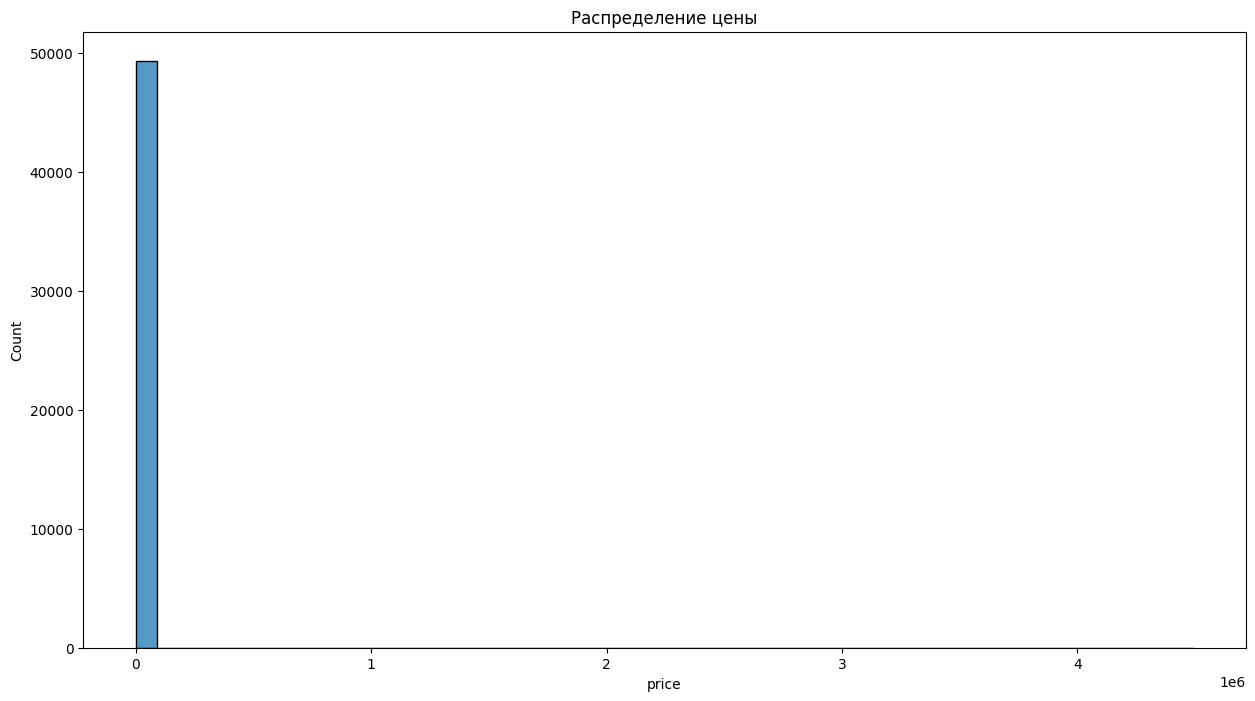

In [9]:
plt.figure(figsize=(15, 8))
sns.histplot(df_train['price'], bins=50)
plt.title('Распределение цены')
plt.show()

График получился не информативный.

#### 3.1.2. Построим коробочный график:

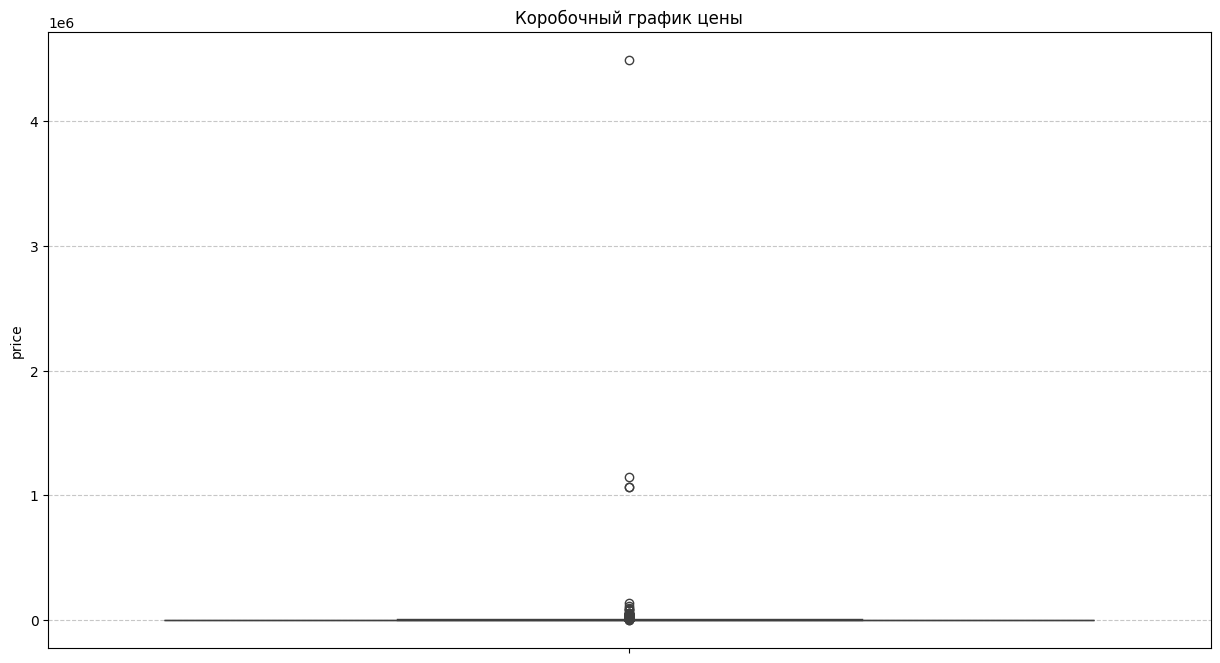

In [10]:
plt.figure(figsize=(15, 8))
sns.boxplot(df_train['price'])
plt.title('Коробочный график цены')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Опять ничего не понятно

#### 3.1.3 Удалим все строки, которые находятся за пределами 1 и 99 процентилей, из целевого столбца:

In [11]:
lower_bound = df_train['price'].quantile(0.01)
upper_bound = df_train['price'].quantile(0.99)

lb_test = df_test['price'].quantile(0.01)
ub_test = df_test['price'].quantile(0.99)
lb_test_bath = df_test['bathrooms'].quantile(0.01)
ub_test_bath = df_test['bathrooms'].quantile(0.99)
lb_test_bed = df_test['bedrooms'].quantile(0.01)
ub_test_bed = df_test['bedrooms'].quantile(0.99)

df_test = df_test[df_test['price'].between(lb_test, ub_test)]
df_test = df_test[df_test['bathrooms'].between(lb_test_bath, ub_test_bath)]
df_test = df_test[df_test['bedrooms'].between(lb_test_bed, ub_test_bed)]

df_train = df_train[df_train['price'].between(lower_bound, upper_bound)]
df_train.info()

<class 'pandas.DataFrame'>
Index: 48379 entries, 4 to 124009
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   bedrooms        48379 non-null  int64  
 1   bathrooms       48379 non-null  float64
 2   interest_level  48379 non-null  str    
 3   price           48379 non-null  int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 1.8 MB


#### 3.1.4. Построим новую гистограмму:

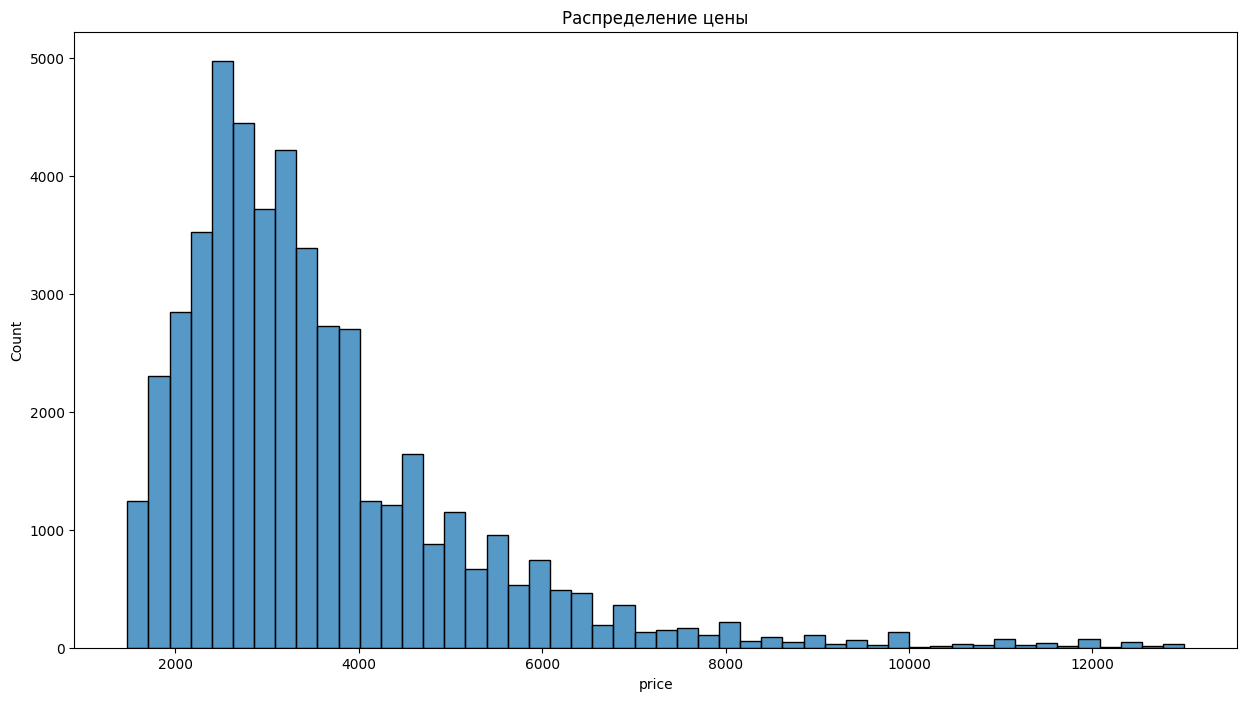

In [12]:
plt.figure(figsize=(15, 8))
sns.histplot(df_train['price'], bins=50)
plt.title('Распределение цены')
plt.show()

Убрав выбросы цены, мы получили корректную гистограмму на которой видно распределение цены. Большее колличество домов продаются по цене 3000-3500.

### 3.2 Анализ характеристик:

#### 3.2.1 Проанализируем столбец "interest_level":

In [13]:
df_train['interest_level'].describe()

count     48379
unique        3
top         low
freq      33697
Name: interest_level, dtype: object

Данный столбец имеет тип "object"

In [14]:
df_train['interest_level'].value_counts()

interest_level
low       33697
medium    11116
high       3566
Name: count, dtype: int64

В данном столбце 3 уникальных значения: "low", "medium", "high"

#### 3.2.2 Закодируем значения:

In [15]:
df_train['interest_level'] = df_train['interest_level'].replace({
    'low': 0,
    'medium': 1,
    'high': 2
})
df_train['interest_level'].value_counts()

interest_level
0    33697
1    11116
2     3566
Name: count, dtype: int64

#### 3.2.3 Построим гистограмму для признаков что бы проверить есть ли выбросы:

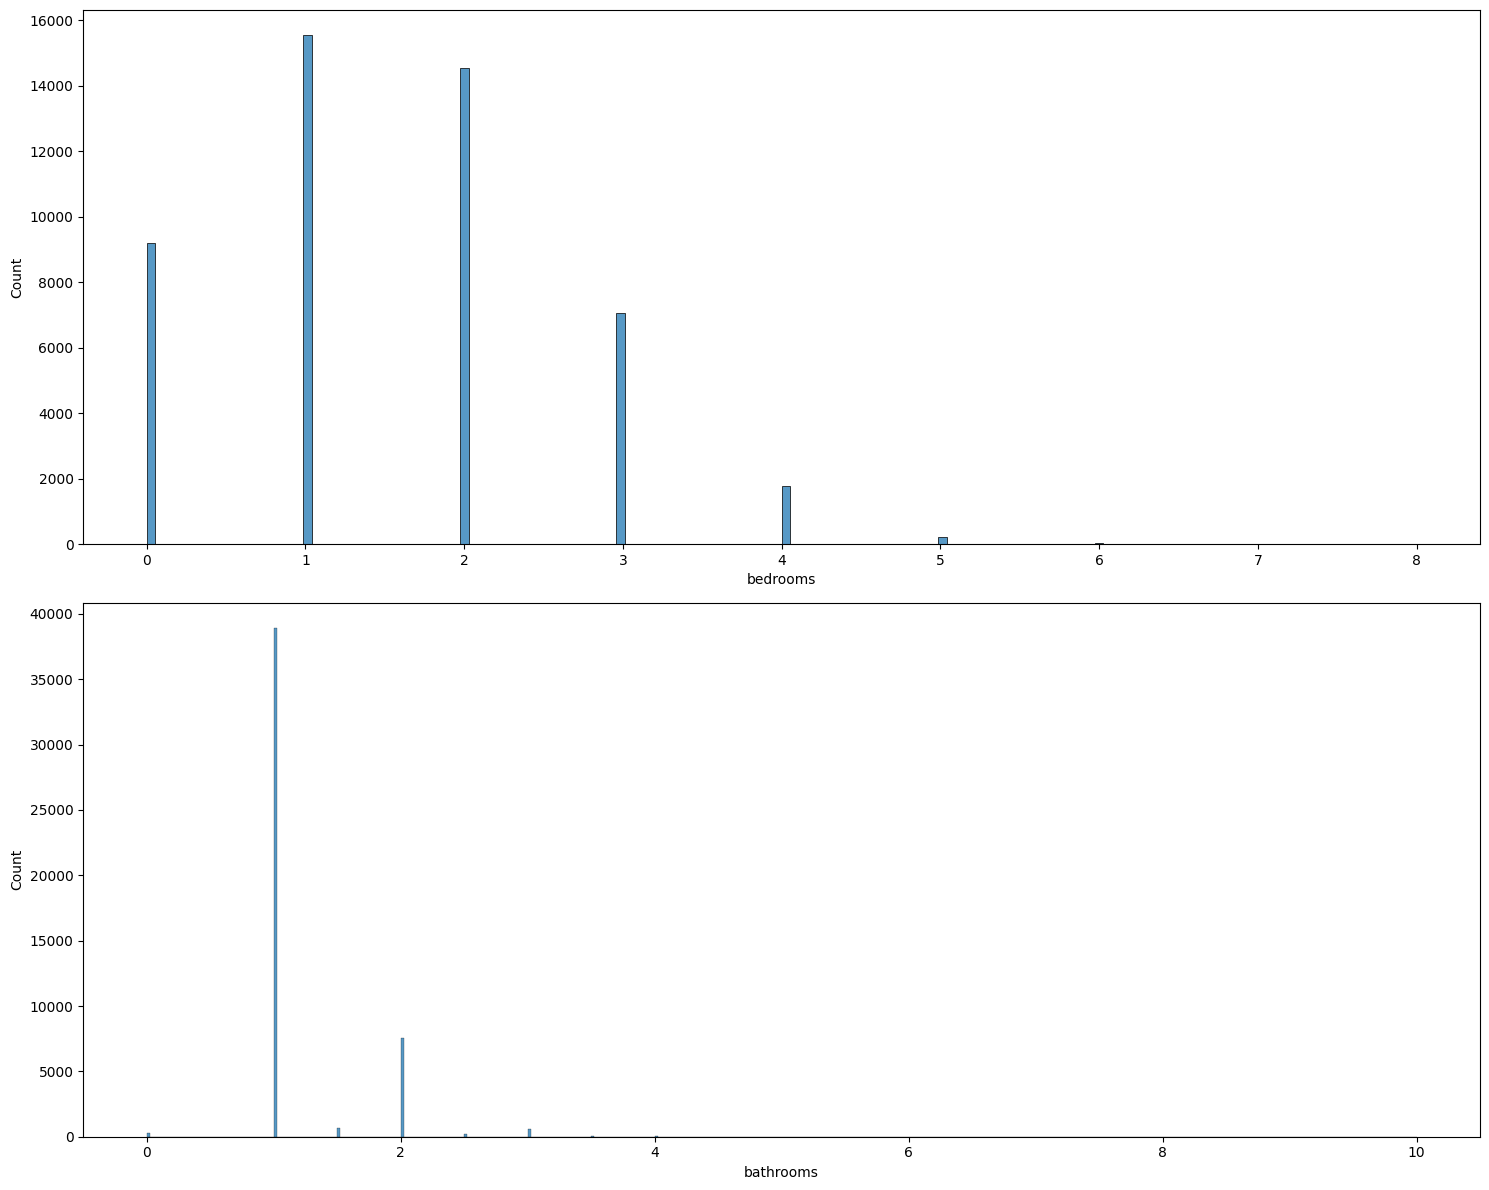

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

sns.histplot(df_train['bedrooms'], ax=axes[0],)

sns.histplot(df_train['bathrooms'], ax=axes[1])

plt.tight_layout()
plt.show()

В признаках "bedrooms", "bathrooms" нет выбросов.

### 3.3 Комплексный анализ:

#### 3.3.1 Построим корреляционную матрицу что бы понять взаимосвязь между признаками и целевыми показателями:

In [17]:
corr = df_train.corr()
corr

,bedrooms,bathrooms,interest_level,price
bedrooms,1.000000,0.517574,0.050654,0.545948
bathrooms,0.517574,1.000000,-0.063635,0.671943
interest_level,0.050654,-0.063635,1.000000,-0.200111
price,0.545948,0.671943,-0.200111,1.000000


#### Построим тепловую карту нашей матрицы:

<Axes: >

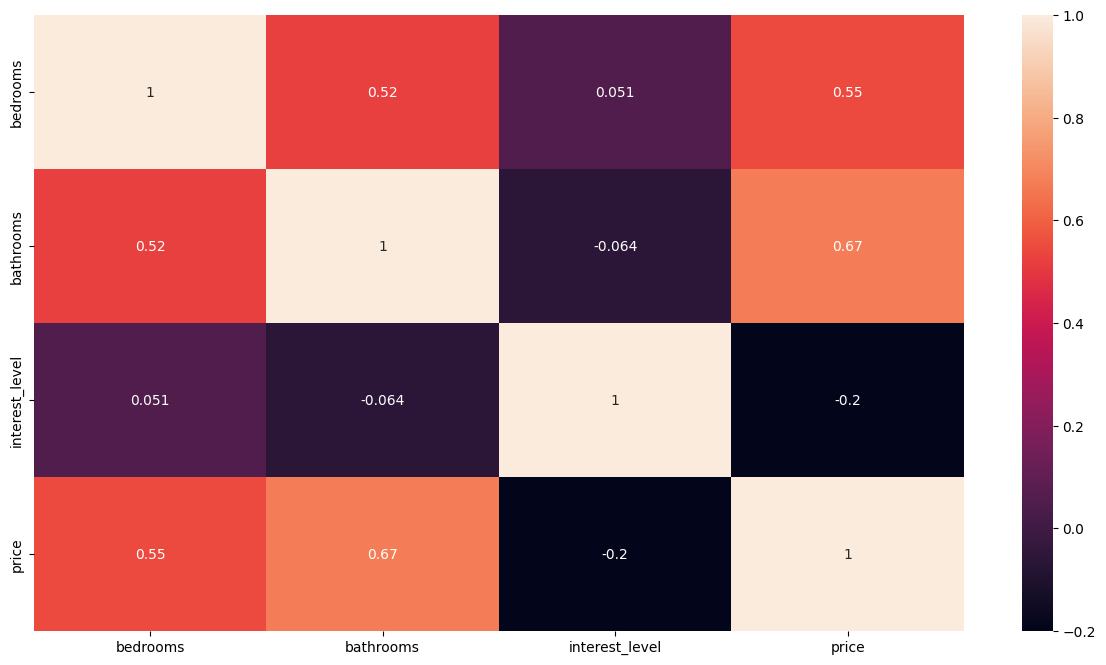

In [18]:
plt.figure(figsize=(15, 8))
sns.heatmap(
    corr,
    annot=True
)

На тепловой карте мы видим наибольшую корреляцию между колличеством ванных и ценой.

#### 3.3.2 Построим диаграмму рассеяния, чтобы визуализировать взаимосвязь между признаками и целевым показателем:

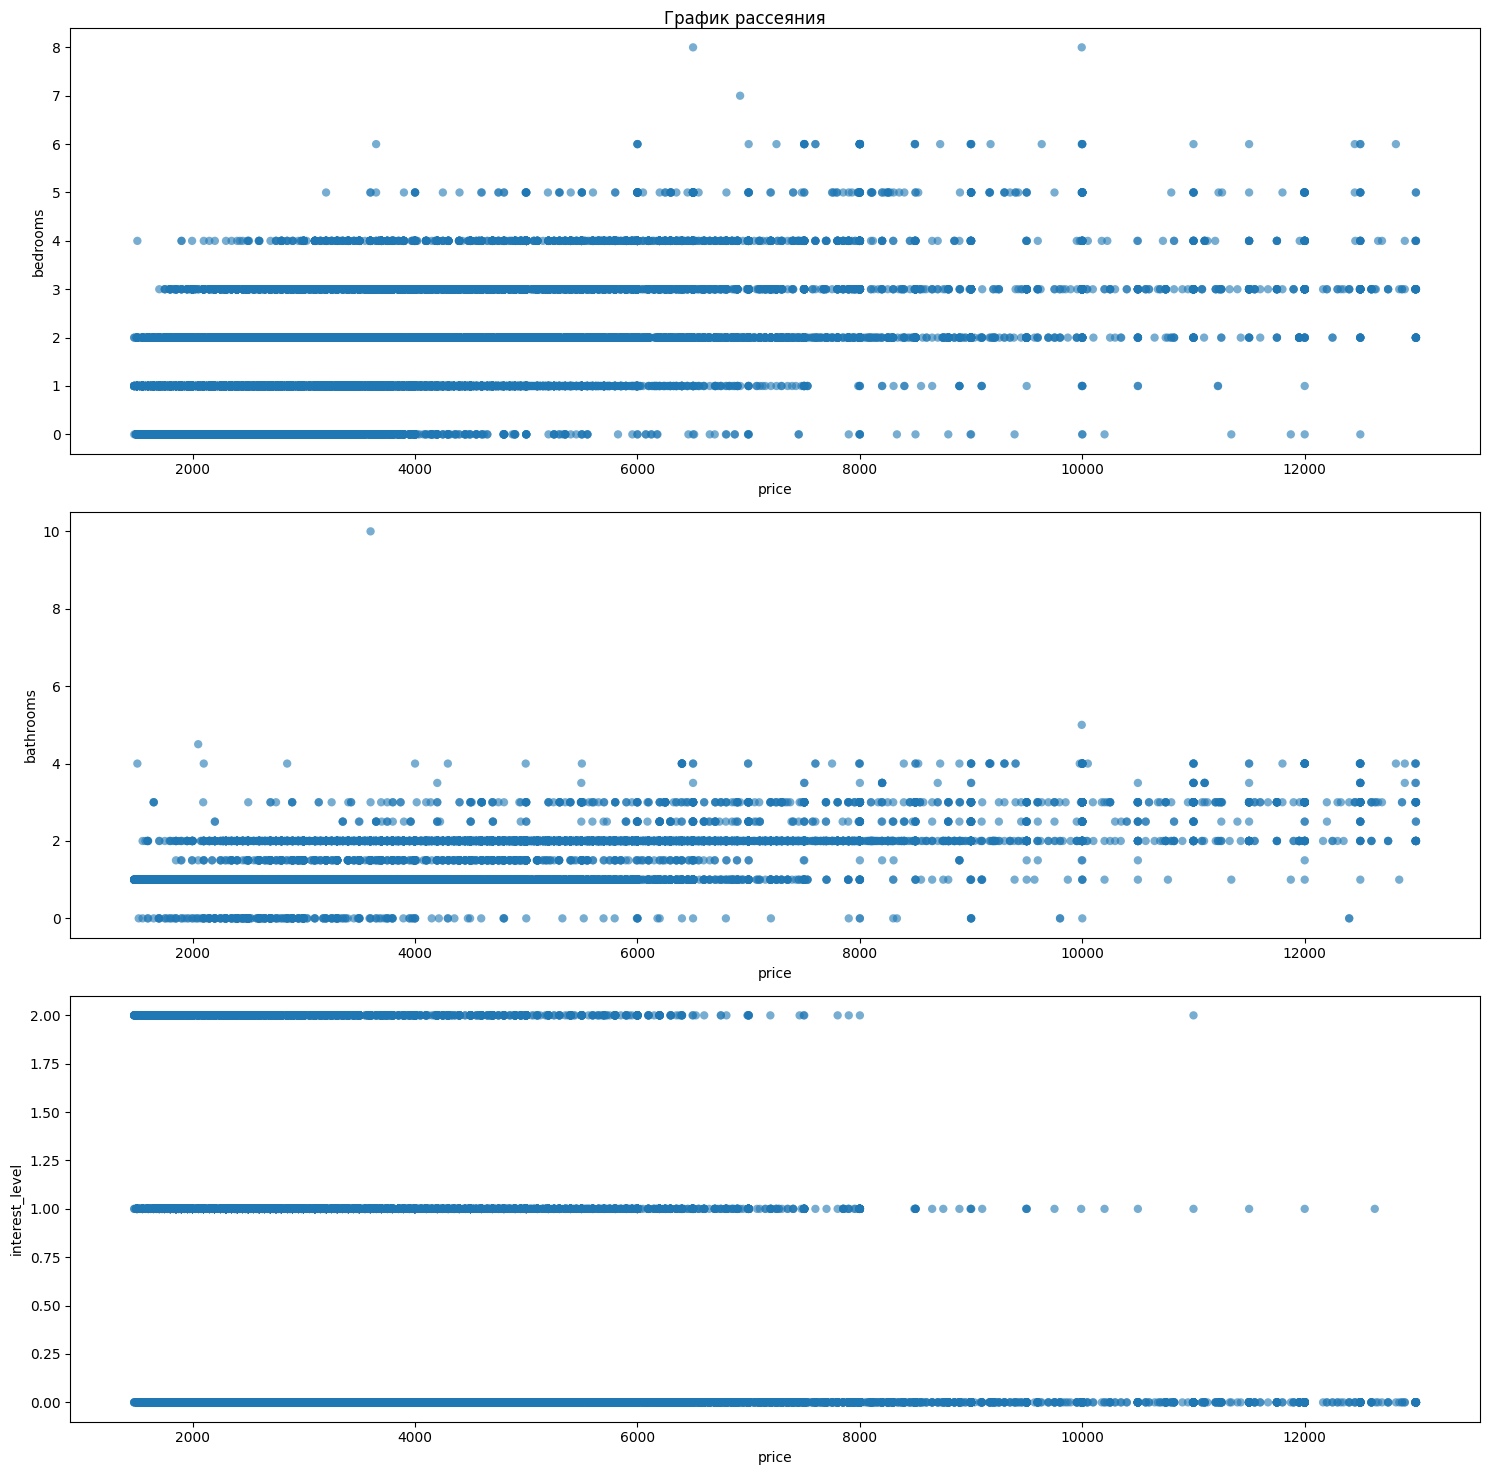

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

sns.scatterplot(
    data=df_train,
    ax=axes[0],
    x='price',
    y='bedrooms',
    alpha=0.6,
    edgecolor='none'
)

sns.scatterplot(
    data=df_train,
    ax=axes[1],
    x='price',
    y='bathrooms',
    alpha=0.6,
    edgecolor='none'
)

sns.scatterplot(
    data=df_train,
    ax=axes[2],
    x='price',
    y='interest_level',
    alpha=0.6,
    edgecolor='none'
)

plt.suptitle('График рассеяния')
plt.tight_layout()
plt.show()

## 4. Создание функций:

### 4.1 Добавление признаков:

Создадим новые признаки, возведя существующие в квадрат, что бы узнать как изменится корреляция с целевой переменной 

In [20]:
df_enriched = df_train.copy()
df_enriched['bathrooms_sqr'] = df_train['bathrooms'] ** 2
df_enriched['bedrooms_sqr'] = df_train['bedrooms'] ** 2
df_enriched['interest_level_sqr'] = df_train['interest_level'] ** 2
df_enriched.info()

<class 'pandas.DataFrame'>
Index: 48379 entries, 4 to 124009
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bedrooms            48379 non-null  int64  
 1   bathrooms           48379 non-null  float64
 2   interest_level      48379 non-null  object 
 3   price               48379 non-null  int64  
 4   bathrooms_sqr       48379 non-null  float64
 5   bedrooms_sqr        48379 non-null  int64  
 6   interest_level_sqr  48379 non-null  object 
dtypes: float64(2), int64(3), object(2)
memory usage: 3.0+ MB


In [21]:
df_enriched.corr()

,bedrooms,bathrooms,interest_level,price,bathrooms_sqr,bedrooms_sqr,interest_level_sqr
bedrooms,1.000000,0.517574,0.050654,0.545948,0.478817,0.928277,0.039511
bathrooms,0.517574,1.000000,-0.063635,0.671943,0.956023,0.548760,-0.059410
interest_level,0.050654,-0.063635,1.000000,-0.200111,-0.068558,0.046340,0.944013
price,0.545948,0.671943,-0.200111,1.000000,0.648486,0.543406,-0.182672
bathrooms_sqr,0.478817,0.956023,-0.068558,0.648486,1.000000,0.522227,-0.062240
bedrooms_sqr,0.928277,0.548760,0.046340,0.543406,0.522227,1.000000,0.035718
interest_level_sqr,0.039511,-0.059410,0.944013,-0.182672,-0.062240,0.035718,1.000000


В полученных данных мы видим что корреляция между квадратичными признаками и целевой преременной практически **не изменилась**

### 4.2 PolynomialFeatures

In [22]:
X_train = df_train.drop(columns=['price', 'interest_level'])
X_test = df_test.drop(columns='price')

y_train = df_train['price']
y_test = df_test['price']

poly = PolynomialFeatures(degree=10)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

feature_names = poly.get_feature_names_out(X_train.columns)

X_test = pd.DataFrame(X_test_poly, columns=feature_names).drop(columns='1')
X_train = pd.DataFrame(X_train_poly, columns=feature_names).drop(columns='1')
X_train

,bedrooms,bathrooms,bedrooms^2,bedrooms bathrooms,bathrooms^2,bedrooms^3,bedrooms^2 bathrooms,bedrooms bathrooms^2,bathrooms^3,bedrooms^4,...,bedrooms^9 bathrooms,bedrooms^8 bathrooms^2,bedrooms^7 bathrooms^3,bedrooms^6 bathrooms^4,bedrooms^5 bathrooms^5,bedrooms^4 bathrooms^6,bedrooms^3 bathrooms^7,bedrooms^2 bathrooms^8,bedrooms bathrooms^9,bathrooms^10
0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.00,1.000,1.0,...,1.0,1.00,1.000,1.0000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2.0,1.0,4.0,2.0,1.00,8.0,4.0,2.00,1.000,16.0,...,512.0,256.00,128.000,64.0000,32.00000,16.000000,8.000000,4.000000,2.000000,1.000000
2,2.0,1.0,4.0,2.0,1.00,8.0,4.0,2.00,1.000,16.0,...,512.0,256.00,128.000,64.0000,32.00000,16.000000,8.000000,4.000000,2.000000,1.000000
3,3.0,1.5,9.0,4.5,2.25,27.0,13.5,6.75,3.375,81.0,...,29524.5,14762.25,7381.125,3690.5625,1845.28125,922.640625,461.320312,230.660156,115.330078,57.665039
4,0.0,1.0,0.0,0.0,1.00,0.0,0.0,0.00,1.000,0.0,...,0.0,0.00,0.000,0.0000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48374,3.0,1.0,9.0,3.0,1.00,27.0,9.0,3.00,1.000,81.0,...,19683.0,6561.00,2187.000,729.0000,243.00000,81.000000,27.000000,9.000000,3.000000,1.000000
48375,2.0,1.0,4.0,2.0,1.00,8.0,4.0,2.00,1.000,16.0,...,512.0,256.00,128.000,64.0000,32.00000,16.000000,8.000000,4.000000,2.000000,1.000000
48376,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.00,1.000,1.0,...,1.0,1.00,1.000,1.0000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
48377,2.0,1.0,4.0,2.0,1.00,8.0,4.0,2.00,1.000,16.0,...,512.0,256.00,128.000,64.0000,32.00000,16.000000,8.000000,4.000000,2.000000,1.000000


## 5. Обучение моделей:

Напишем функцию для обуения моделей и расчета MAE и RMSE:

In [23]:
def results(models, X_test, X_train, y_test, y_train):
    
    cols = ['model', 'train', 'test']
    result_MAE = pd.DataFrame(columns=cols)
    result_RMSE = pd.DataFrame(columns=cols)

    models_name = []
    train_mae = []
    train_rmse = []
    test_mae = []
    test_rmse = []

    for model in models:
        
        model.fit(X_train, y_train)
        model_pred_train = model.predict(X_train)
        model_pred_test = model.predict(X_test)

        mae_train = mean_absolute_error(y_train, model_pred_train)
        mae_test = mean_absolute_error(y_test, model_pred_test)

        rmse_train = np.sqrt(mean_squared_error(y_train, model_pred_train))
        rmse_test = np.sqrt(mean_squared_error(y_test, model_pred_test))

        models_name.append(model.__class__.__name__)
        train_mae.append(mae_train)
        train_rmse.append(rmse_train)
        test_mae.append(mae_test)
        test_rmse.append(rmse_test)

    
    result_MAE['model'] = models_name
    result_MAE['train'] = train_mae
    result_MAE['test'] = test_mae

    result_RMSE['model'] = models_name
    result_RMSE['train'] = train_rmse
    result_RMSE['test'] = test_rmse
    
    return result_MAE, result_RMSE

In [24]:
models = [LinearRegression(), DecisionTreeRegressor(random_state=21)]
result_MAE, result_RMSE = results(models, X_test, X_train, y_test, y_train)

In [25]:
result_RMSE

,model,train,test
0,LinearRegression,1077.566356,1609.872549
1,DecisionTreeRegressor,1077.483596,1070.433552


In [26]:
result_MAE

,model,train,test
0,LinearRegression,756.040300,763.961073
1,DecisionTreeRegressor,756.044735,753.440602


 Вычислим среднее значение и медиану для 'price' в обучающих и тестовых данных:

In [27]:
mean_train = np.full_like(y_train, y_train.mean())
mean_test = np.full_like(y_test, y_test.mean())

median_train = np.full_like(y_train, y_train.median())
median_test = np.full_like(y_test, y_test.median())

Вычислим значения MAE и RMSE и вставим результаты в таблицу:

In [28]:
mae_train_mean = mean_absolute_error(y_train, mean_train)
mae_test_mean = mean_absolute_error(y_test, mean_test)
mae_train_median = mean_absolute_error(y_train, median_train)
mae_test_median = mean_absolute_error(y_test, median_test)

rmse_train_mean = np.sqrt(mean_squared_error(y_train, mean_train))
rmse_test_mean = np.sqrt(mean_squared_error(y_test, mean_test))
rmse_train_median = np.sqrt(mean_squared_error(y_train, median_train))
rmse_test_median = np.sqrt(mean_squared_error(y_test, median_test))

In [29]:
naive_mae = pd.DataFrame({'model': ['naive_mean', 'naive_median'], 'train': [mae_train_mean, mae_train_median], 'test': [mae_test_mean, mae_test_median]})
naive_rmse = pd.DataFrame({'model': ['naive_mean', 'naive_median'], 'train': [rmse_train_mean, rmse_train_median], 'test': [rmse_test_mean, rmse_test_median]})

result_MAE = pd.concat([result_MAE, naive_mae], ignore_index=True)
result_RMSE = pd.concat([result_RMSE, naive_rmse], ignore_index=True)

In [30]:
result_MAE

,model,train,test
0,LinearRegression,756.040300,763.961073
1,DecisionTreeRegressor,756.044735,753.440602
2,naive_mean,1139.022179,1108.168277
3,naive_median,1086.210505,1062.160412


In [31]:
result_RMSE

,model,train,test
0,LinearRegression,1077.566356,1609.872549
1,DecisionTreeRegressor,1077.483596,1070.433552
2,naive_mean,1597.646782,1541.583985
3,naive_median,1644.236439,1582.606001


Исходя из полученных данных, делаем вывод что лучше всех справилась модель **DecisionTreeRegressor**.